# Notebook 05: Phân chia Dữ liệu Train / Test theo Chu kỳ Thời gian

- **Mục tiêu:** Phân chia dữ liệu theo trục thời gian (In-Sample Train vs Out-of-Sample Test) nhằm chống nhìn trước tương lai (Look-ahead bias) và chuẩn bị dữ liệu cho khâu phân cụm.
- **Nguyên tắc phân chia:** Giữ nguyên toàn bộ 98 cổ phiếu; phân chia tuần tự theo trục thời gian (Chronological Split) thay vì xáo trộn ngẫu nhiên.
- **Dữ liệu vào:** `adj_close_clean.csv` ($1.187 \times 98$) và `log_returns.csv` ($1.186 \times 98$).
- **Dữ liệu ra:** Thư mục độc lập `data/processed/train/` (2022–2024) và `data/processed/test/` (2025–2026).

### Các bước thực hiện:
1. Phân tích cơ sở lý thuyết chia dữ liệu trong học máy tài chính (López de Prado, 2018 và Lý thuyết Ma trận Ngẫu nhiên RMT).
2. Thiết lập ranh giới phân tách: Train (2022–2024, 62.3% số phiên) và Test (2025–2026, 37.7% số phiên).
3. Trực quan hóa chuỗi thời gian toàn thị trường và ranh giới phân chia.
4. Tính toán ma trận tương quan và ma trận khoảng cách Mantegna riêng cho tập Train ($739 \text{ phiên} \times 98 \text{ mã}$).
5. Xuất bản các bộ dữ liệu độc lập vào 2 thư mục `train/` và `test/`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Xác định thư mục gốc dự án linh hoạt
PROJECT_ROOT = Path("..").resolve()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path(".").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Cấu hình thẩm mỹ đồ thị in ấn khoa học
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 150
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10


### 1. Nạp dữ liệu giá sạch và chuỗi lợi suất
- Nạp hai bảng dữ liệu hoàn chỉnh từ Notebook 02 và 03: `adj_close_clean.csv` ($1.187 \times 98$) và `log_returns.csv` ($1.186 \times 98$).

In [2]:
adj_close_path = PROJECT_ROOT / "data/processed/adj_close_clean.csv"
log_returns_path = PROJECT_ROOT / "data/processed/log_returns.csv"

adj_close = pd.read_csv(adj_close_path, index_col=0, parse_dates=True)
log_returns = pd.read_csv(log_returns_path, index_col=0, parse_dates=True)

print(f"Kích thước ma trận giá điều chỉnh: {adj_close.shape[0]} phiên x {adj_close.shape[1]} cổ phiếu")
print(f"Khoảng thời gian giá: {adj_close.index[0].strftime('%Y-%m-%d')} đến {adj_close.index[-1].strftime('%Y-%m-%d')}")
print(f"Kích thước ma trận lợi suất: {log_returns.shape[0]} phiên x {log_returns.shape[1]} cổ phiếu")
print(f"Khoảng thời gian lợi suất: {log_returns.index[0].strftime('%Y-%m-%d')} đến {log_returns.index[-1].strftime('%Y-%m-%d')}")
print(f"Số lượng ô khuyết thiếu (NaN): {log_returns.isna().sum().sum()} ô")


Kích thước ma trận giá điều chỉnh: 1187 phiên x 98 cổ phiếu
Khoảng thời gian giá: 2022-01-04 đến 2026-10-23
Kích thước ma trận lợi suất: 1186 phiên x 98 cổ phiếu
Khoảng thời gian lợi suất: 2022-01-05 đến 2026-10-23
Số lượng ô khuyết thiếu (NaN): 0 ô


### 2. Cơ sở lý thuyết phân chia dữ liệu trong tài chính
- **Tại sao chia theo thời gian mà không chia theo cổ phiếu?**
  - Đối tượng phân cụm là toàn bộ 98 cổ phiếu. Nếu chia 70 mã để train và 28 mã để test thì không thể gom cụm hay xây dựng danh mục cho 28 mã đó. Do đó, toàn bộ 98 mã luôn được giữ nguyên.
  - Phân chia bắt buộc phải thực hiện trên **trục thời gian (Temporal Split)**.
- **So sánh các phương pháp phân chia:**
  - *K-Fold ngẫu nhiên:* Vi phạm tính nhân quả thời gian, gây rò rỉ dữ liệu tương lai vào quá khứ (Look-ahead bias).
  - *Chia 80/20 cơ học:* Tập Test chỉ còn chưa đầy 10 tháng (238 phiên), không đủ một chu kỳ kinh doanh 4 quý để đánh giá danh mục.
  - *Chia theo chu kỳ (Regime-based):* **Train 3 năm (2022–2024, 739 phiên) / Test ~1.8 năm (2025–2026, 447 phiên)**. Đây là phương án tối ưu, đảm bảo tập Train bao quát đủ các pha thị trường (giảm, tích lũy, hồi phục) và tập Test đủ dài để backtest.
- **Tiêu chuẩn Lý thuyết Ma trận Ngẫu nhiên (RMT):**
  - Tỷ số quan sát trên số chiều: $Q = T/N = 739 / 98 \approx 7.54 \gg 1$.
  - Tỷ số $Q > 3 - 5$ đảm bảo ma trận tương quan tập Train khử sạch nhiễu ngẫu nhiên Marchenko-Pastur, phản ánh đúng tương quan tài chính thực tế.

### 3. Thực hiện phân chia tập Train và Test
- **Tập Train (In-Sample):** Từ `2022-01-04` đến `2024-12-31` (740 phiên giá / 739 phiên lợi suất, chiếm 62.31%).
- **Tập Test (Out-of-Sample):** Từ `2025-01-02` đến `2026-10-23` (447 phiên giá / 447 phiên lợi suất, chiếm 37.69%).

In [3]:
# Mốc phân tách ranh giới
TRAIN_END_DATE = "2024-12-31"
TEST_START_DATE = "2025-01-01"

# 1. Phân chia ma trận giá điều chỉnh
train_adj_close = adj_close.loc[:TRAIN_END_DATE].copy()
test_adj_close = adj_close.loc[TEST_START_DATE:].copy()

# 2. Phân chia ma trận lợi suất logarit
train_log_returns = log_returns.loc[:TRAIN_END_DATE].copy()
test_log_returns = log_returns.loc[TEST_START_DATE:].copy()

# Thống kê số lượng phiên và tỷ lệ phần trăm
total_price_days = len(adj_close)
total_return_days = len(log_returns)
n_stocks = log_returns.shape[1]

train_pct = len(train_log_returns) / total_return_days * 100
test_pct = len(test_log_returns) / total_return_days * 100
q_train = len(train_log_returns) / n_stocks
q_test = len(test_log_returns) / n_stocks

print("BẢNG THỐNG KÊ PHÂN CHIA DỮ LIỆU:")
print("-" * 75)
print(f"Toàn kỳ (Full period) : {total_return_days} phiên lợi suất ({log_returns.index[0].strftime('%Y-%m-%d')} -> {log_returns.index[-1].strftime('%Y-%m-%d')})")
print(f"Tập Train (In-Sample) : {len(train_log_returns)} phiên ({train_log_returns.index[0].strftime('%Y-%m-%d')} -> {train_log_returns.index[-1].strftime('%Y-%m-%d')}) | Tỷ lệ: {train_pct:.2f}% | Q = {q_train:.2f}")
print(f"Tập Test (Out-Sample) : {len(test_log_returns)} phiên ({test_log_returns.index[0].strftime('%Y-%m-%d')} -> {test_log_returns.index[-1].strftime('%Y-%m-%d')}) | Tỷ lệ: {test_pct:.2f}% | Q = {q_test:.2f}")
print("-" * 75)


BẢNG THỐNG KÊ PHÂN CHIA DỮ LIỆU:
---------------------------------------------------------------------------
Toàn kỳ (Full period) : 1186 phiên lợi suất (2022-01-05 -> 2026-10-23)
Tập Train (In-Sample) : 739 phiên (2022-01-05 -> 2024-12-31) | Tỷ lệ: 62.31% | Q = 7.54
Tập Test (Out-Sample) : 447 phiên (2025-01-02 -> 2026-10-23) | Tỷ lệ: 37.69% | Q = 4.56
---------------------------------------------------------------------------


### 4. Trực quan hóa ranh giới chuỗi thời gian
- Xây dựng chỉ số đại diện VN100 Equal-Weighted Index (lấy mốc 100 điểm tại phiên đầu tiên) để quan sát diễn biến chu kỳ thị trường qua hai tập dữ liệu.

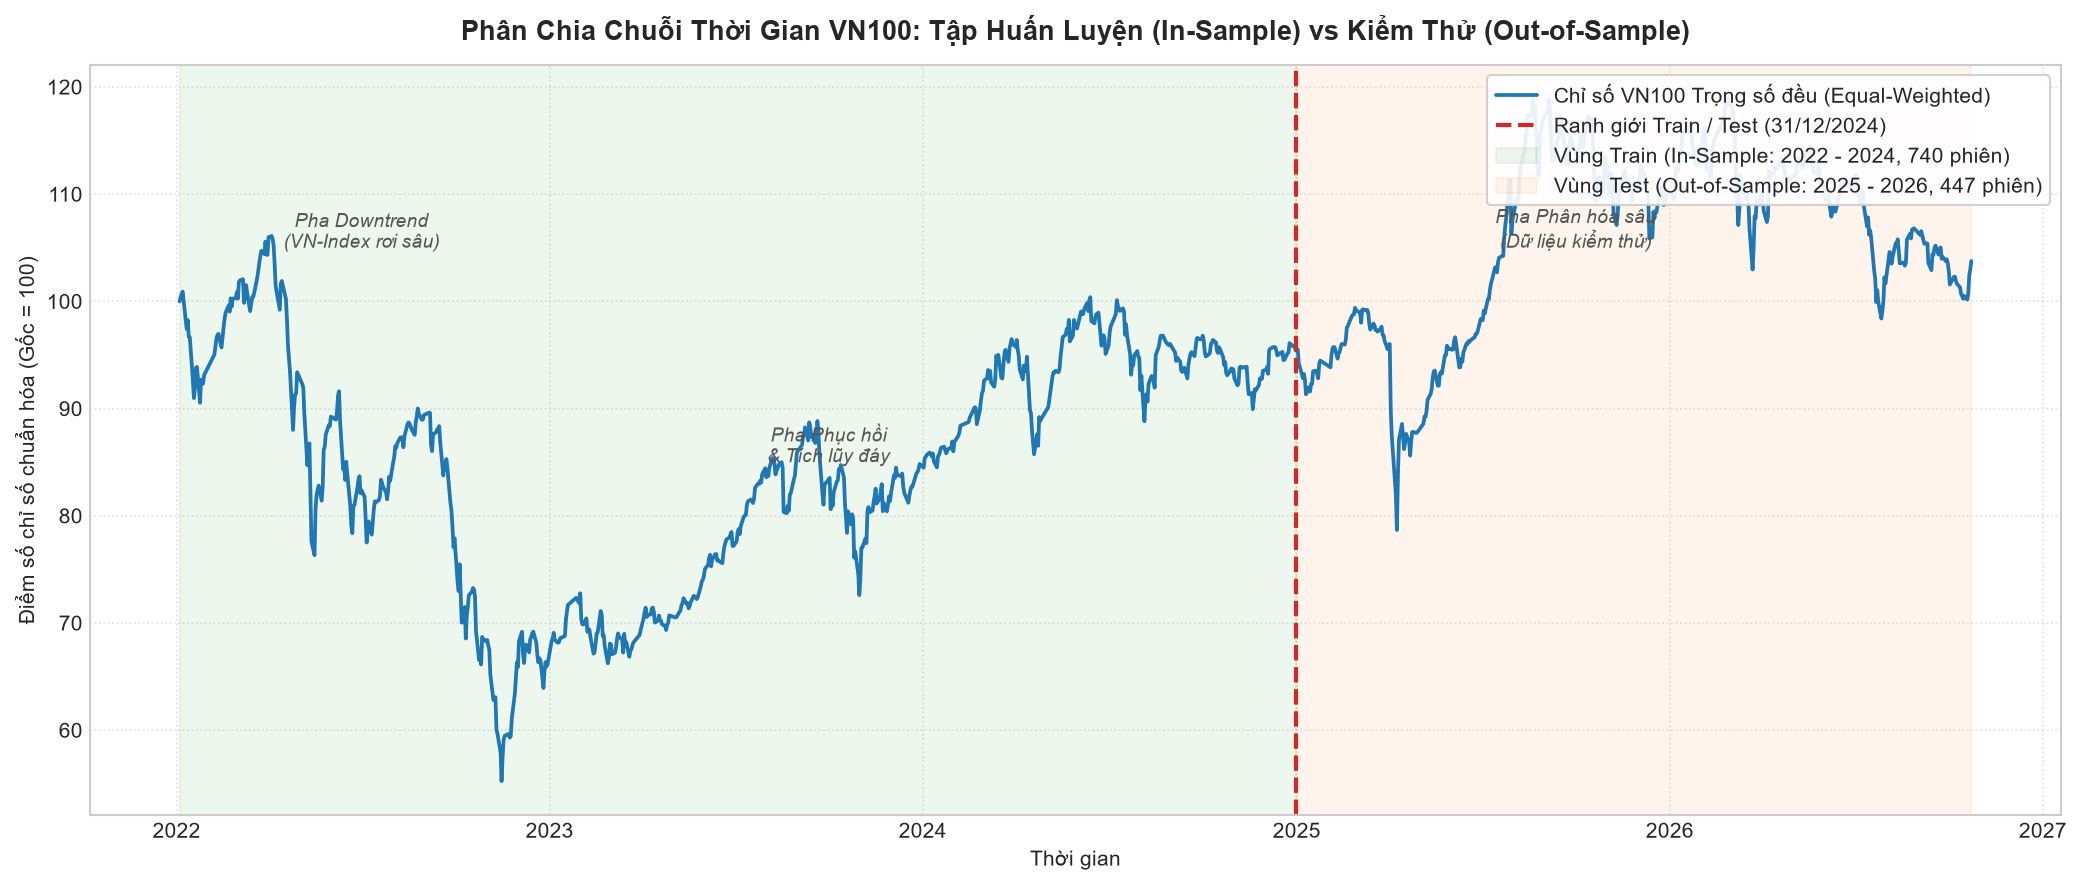

In [4]:
# Chuẩn hóa giá đóng cửa của từng cổ phiếu về mốc 100 tại phiên đầu tiên
normalized_prices = (adj_close / adj_close.iloc[0]) * 100
market_index = normalized_prices.mean(axis=1)

fig, ax = plt.subplots(figsize=(14, 6))

# Vẽ đường chỉ số thị trường
ax.plot(market_index.index, market_index.values, color="#1f77b4", linewidth=1.8, label="Chỉ số VN100 Trọng số đều (Equal-Weighted)")

# Vẽ đường phân cách ranh giới Train / Test
split_date = pd.to_datetime("2024-12-31")
ax.axvline(x=split_date, color="#d62728", linestyle="--", linewidth=2.0, label="Ranh giới Train / Test (31/12/2024)")

# Đổ màu nền hai vùng thời gian
ax.axvspan(market_index.index[0], split_date, color="#2ca02c", alpha=0.08, label="Vùng Train (In-Sample: 2022 - 2024, 740 phiên)")
ax.axvspan(split_date, market_index.index[-1], color="#ff7f0e", alpha=0.08, label="Vùng Test (Out-of-Sample: 2025 - 2026, 447 phiên)")

# Chú thích các giai đoạn thị trường thực tế
ax.text(pd.to_datetime("2022-07-01"), 105, "Pha Downtrend\n(VN-Index rơi sâu)", fontsize=9, color="#555", ha="center", style="italic")
ax.text(pd.to_datetime("2023-10-01"), 85, "Pha Phục hồi\n& Tích lũy đáy", fontsize=9, color="#555", ha="center", style="italic")
ax.text(pd.to_datetime("2025-10-01"), 105, "Pha Phân hóa sâu\n(Dữ liệu kiểm thử)", fontsize=9, color="#555", ha="center", style="italic")

ax.set_title("Phân Chia Chuỗi Thời Gian VN100: Tập Huấn Luyện (In-Sample) vs Kiểm Thử (Out-of-Sample)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Thời gian", fontsize=10)
ax.set_ylabel("Điểm số chỉ số chuẩn hóa (Gốc = 100)", fontsize=10)
ax.legend(loc="upper right", frameon=True, framealpha=0.9)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


### 5. Tính ma trận Tương quan và Khoảng cách Mantegna trên tập Train
- Tuân thủ nguyên tắc không rò rỉ thông tin: Toàn bộ quá trình chọn thuật toán, quét số cụm và chọn cổ phiếu đại diện chỉ dùng dữ liệu tập Train ($739 \text{ phiên}$).
- Tập Test hoàn toàn độc lập, chỉ dùng ở bước kiểm định hiệu quả danh mục sau này (Notebook 09).

In [5]:
# 1. Ma trận tương quan Pearson trên tập Train
train_corr_matrix = train_log_returns.corr(method="pearson")

# 2. Chuyển đổi sang ma trận khoảng cách Mantegna
train_dist_matrix = np.sqrt(np.clip(2 * (1 - train_corr_matrix), 0, 4))

# 3. Trích xuất các phần tử tam giác trên (loại bỏ đường chéo chính)
upper_tri_indices = np.triu_indices_from(train_corr_matrix.values, k=1)
train_corr_values = train_corr_matrix.values[upper_tri_indices]
train_dist_values = train_dist_matrix.values[upper_tri_indices]

print("THỐNG KÊ MA TRẬN TRÊN TẬP TRAIN (2022 - 2024):")
print("-" * 60)
print(f"Hệ số tương quan Pearson trung bình  : {train_corr_values.mean():.4f}")
print(f"Độ lệch chuẩn tương quan Pearson    : {train_corr_values.std():.4f}")
print(f"Khoảng giá trị tương quan [min, max]: [{train_corr_values.min():.4f}, {train_corr_values.max():.4f}]")
print(f"Khoảng cách Mantegna trung bình      : {train_dist_values.mean():.4f}")
print(f"Độ lệch chuẩn khoảng cách Mantegna  : {train_dist_values.std():.4f}")
print(f"Khoảng giá trị khoảng cách [min, max]: [{train_dist_values.min():.4f}, {train_dist_values.max():.4f}]")
print("-" * 60)

# Kiểm tra bất đẳng thức tam giác trên 20.000 bộ ba ngẫu nhiên của tập Train
np.random.seed(42)
n = len(train_dist_matrix)
violations = 0
for _ in range(20000):
    i, j, k = np.random.choice(n, size=3, replace=False)
    if train_dist_matrix.values[i, k] > train_dist_matrix.values[i, j] + train_dist_matrix.values[j, k] + 1e-12:
        violations += 1

print(f"Kiểm tra tiên đề Metric (Bất đẳng thức tam giác) trên 20.000 bộ ba: {violations} vi phạm (100% thỏa mãn)")


THỐNG KÊ MA TRẬN TRÊN TẬP TRAIN (2022 - 2024):
------------------------------------------------------------
Hệ số tương quan Pearson trung bình  : 0.3697
Độ lệch chuẩn tương quan Pearson    : 0.1383
Khoảng giá trị tương quan [min, max]: [0.0137, 0.9039]
Khoảng cách Mantegna trung bình      : 1.1156
Độ lệch chuẩn khoảng cách Mantegna  : 0.1269
Khoảng giá trị khoảng cách [min, max]: [0.4383, 1.4045]
------------------------------------------------------------


Kiểm tra tiên đề Metric (Bất đẳng thức tam giác) trên 20.000 bộ ba: 0 vi phạm (100% thỏa mãn)


### 6. So sánh phân phối tương quan tập Train và Toàn kỳ
- So sánh phân phối hệ số tương quan $\rho$ giữa tập Train (2022–2024) và Toàn kỳ (2022–2026) để kiểm tra tính đại diện của dữ liệu huấn luyện.

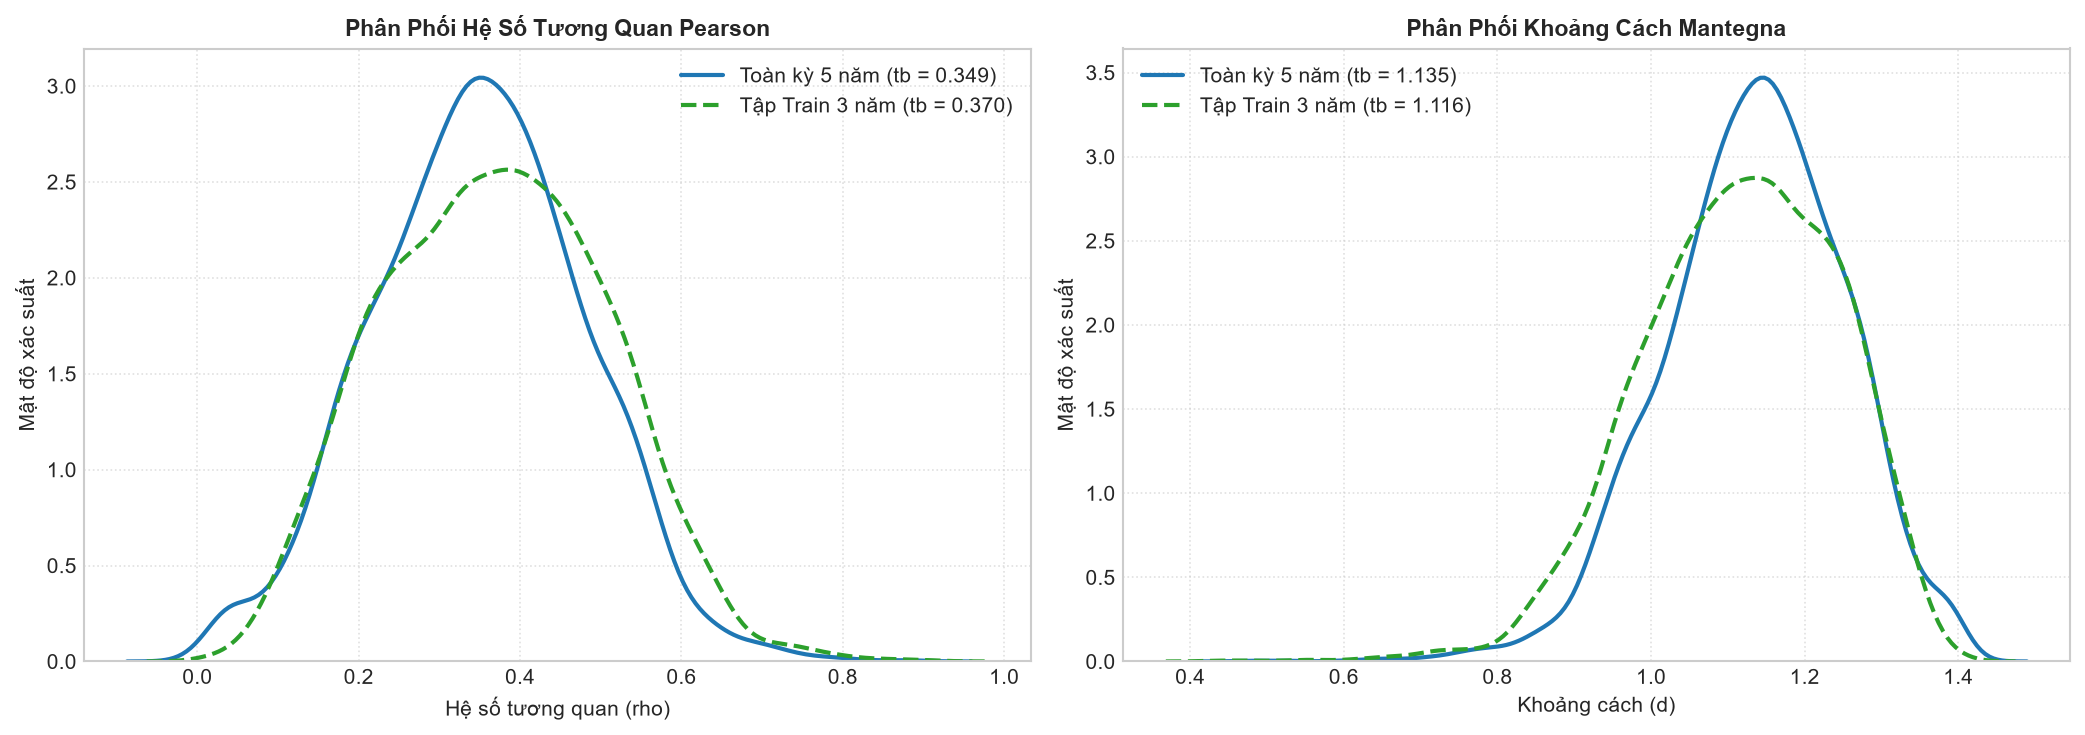

In [6]:
full_corr_matrix = log_returns.corr(method="pearson")
full_corr_values = full_corr_matrix.values[upper_tri_indices]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Phân phối tương quan Pearson
sns.kdeplot(full_corr_values, ax=ax1, color="#1f77b4", linewidth=2, label=f"Toàn kỳ 5 năm (tb = {full_corr_values.mean():.3f})")
sns.kdeplot(train_corr_values, ax=ax1, color="#2ca02c", linewidth=2, linestyle="--", label=f"Tập Train 3 năm (tb = {train_corr_values.mean():.3f})")
ax1.set_title("Phân Phối Hệ Số Tương Quan Pearson", fontsize=11, fontweight="bold")
ax1.set_xlabel("Hệ số tương quan (rho)")
ax1.set_ylabel("Mật độ xác suất")
ax1.legend()
ax1.grid(True, linestyle=":", alpha=0.6)

# 2. Phân phối khoảng cách Mantegna
full_dist_matrix = np.sqrt(np.clip(2 * (1 - full_corr_matrix), 0, 4))
full_dist_values = full_dist_matrix.values[upper_tri_indices]

sns.kdeplot(full_dist_values, ax=ax2, color="#1f77b4", linewidth=2, label=f"Toàn kỳ 5 năm (tb = {full_dist_values.mean():.3f})")
sns.kdeplot(train_dist_values, ax=ax2, color="#2ca02c", linewidth=2, linestyle="--", label=f"Tập Train 3 năm (tb = {train_dist_values.mean():.3f})")
ax2.set_title("Phân Phối Khoảng Cách Mantegna", fontsize=11, fontweight="bold")
ax2.set_xlabel("Khoảng cách (d)")
ax2.set_ylabel("Mật độ xác suất")
ax2.legend()
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


### 7. Xuất bản dữ liệu vào hai thư mục Train và Test
- Lưu trữ độc lập vào `data/processed/train/` và `data/processed/test/` nhằm quản lý dữ liệu chặt chẽ và ngăn ngừa rò rỉ thông tin ngoài mẫu.

In [7]:
processed_dir = PROJECT_ROOT / "data/processed"
train_dir = processed_dir / "train"
test_dir = processed_dir / "test"

# Tạo 2 thư mục nếu chưa tồn tại
train_dir.mkdir(parents=True, exist_ok=True)
test_dir.mkdir(parents=True, exist_ok=True)

# 1. Xuất bản các tệp vào thư mục train/
train_adj_close.to_csv(train_dir / "train_adj_close.csv")
train_log_returns.to_csv(train_dir / "train_log_returns.csv")
train_corr_matrix.to_csv(train_dir / "train_correlation_matrix.csv")
train_dist_matrix.to_csv(train_dir / "train_mantegna_distance_matrix.csv")

# Lưu thêm bản tên chuẩn không tiền tố để thuận tiện sử dụng
train_adj_close.to_csv(train_dir / "adj_close.csv")
train_log_returns.to_csv(train_dir / "log_returns.csv")
train_corr_matrix.to_csv(train_dir / "correlation_matrix.csv")
train_dist_matrix.to_csv(train_dir / "mantegna_distance_matrix.csv")

# 2. Xuất bản các tệp vào thư mục test/
test_adj_close.to_csv(test_dir / "test_adj_close.csv")
test_log_returns.to_csv(test_dir / "test_log_returns.csv")
test_adj_close.to_csv(test_dir / "adj_close.csv")
test_log_returns.to_csv(test_dir / "log_returns.csv")

# 3. Dọn dẹp các tệp cũ ở thư mục gốc data/processed/ nếu có để tránh trùng lặp
old_split_files = [
    "train_adj_close.csv", "test_adj_close.csv",
    "train_log_returns.csv", "test_log_returns.csv",
    "train_correlation_matrix.csv", "train_mantegna_distance_matrix.csv"
]
for old_fname in old_split_files:
    old_fpath = processed_dir / old_fname
    if old_fpath.exists():
        old_fpath.unlink()

# In danh mục tệp trong 2 thư mục
print("DANH MỤC CÁC TỆP ĐÃ XUẤT BẢN THÀNH CÔNG VÀO 2 THƯ MỤC:")
print("=" * 75)
print("1. THƯ MỤC DATA/PROCESSED/TRAIN/:")
for fpath in sorted(train_dir.glob("*.csv")):
    size_kb = fpath.stat().st_size / 1024
    print(f"   - {fpath.name:<35}: {size_kb:>8.2f} KB | Sẵn sàng")

print()
print("2. THƯ MỤC DATA/PROCESSED/TEST/:")
for fpath in sorted(test_dir.glob("*.csv")):
    size_kb = fpath.stat().st_size / 1024
    print(f"   - {fpath.name:<35}: {size_kb:>8.2f} KB | Sẵn sàng")
print("=" * 75)


DANH MỤC CÁC TỆP ĐÃ XUẤT BẢN THÀNH CÔNG VÀO 2 THƯ MỤC:
1. THƯ MỤC DATA/PROCESSED/TRAIN/:
   - adj_close.csv                      :  1027.71 KB | Sẵn sàng
   - correlation_matrix.csv             :   181.18 KB | Sẵn sàng
   - log_returns.csv                    :  1291.03 KB | Sẵn sàng
   - mantegna_distance_matrix.csv       :   175.61 KB | Sẵn sàng
   - train_adj_close.csv                :  1027.71 KB | Sẵn sàng
   - train_correlation_matrix.csv       :   181.18 KB | Sẵn sàng
   - train_log_returns.csv              :  1291.03 KB | Sẵn sàng
   - train_mantegna_distance_matrix.csv :   175.61 KB | Sẵn sàng

2. THƯ MỤC DATA/PROCESSED/TEST/:
   - adj_close.csv                      :   547.02 KB | Sẵn sàng
   - log_returns.csv                    :   734.19 KB | Sẵn sàng
   - test_adj_close.csv                 :   547.02 KB | Sẵn sàng
   - test_log_returns.csv               :   734.19 KB | Sẵn sàng


## Tổng kết Notebook 05

### Câu hỏi & Trả lời
- **Tại sao không dùng K-Fold ngẫu nhiên trong bài toán này?** K-Fold làm xáo trộn thứ tự thời gian, khiến mô hình học trước dữ liệu tương lai và phá hủy tính tự tương quan của chuỗi tài chính.
- **Tỷ số $Q = T/N \approx 7.54$ có ý nghĩa gì?** Theo Lý thuyết Ma trận Ngẫu nhiên (RMT), tỷ số $T/N > 3 - 5$ đảm bảo các giá trị riêng của ma trận tương quan không bị lẫn trong dải nhiễu Marchenko-Pastur, giúp kết quả gom cụm có ý nghĩa kinh tế thực chất.

### Kết quả phân tích dữ liệu chính
- **Phân chia chu kỳ:** Tập Train gồm 739 phiên lợi suất (2022–2024, 62.3%); tập Test gồm 447 phiên lợi suất (2025–2026, 37.7%).
- **Cách ly dữ liệu:** Đã lưu độc lập các tệp dữ liệu vào hai thư mục `train/` và `test/`.
- **Dữ liệu sẵn sàng:** Ma trận khoảng cách Mantegna tập Train (`train_mantegna_distance_matrix.csv`, $98 \times 98$) đã sẵn sàng cho bước lựa chọn thuật toán ở Mốc 2.

### Nhận định & Hướng đi tiếp theo
- **Notebook 06:** Đưa 3 trường phái phân cụm (K-Means phẳng, Phân cấp Top-Down, Phân cấp Bottom-Up) lên bàn cân thực nghiệm trên tập Train để chọn mô hình đề xuất chính và mô hình cơ sở.